# Option Price Diagnostics and Put-Call Parity


**Model inputs:** S? = 100 | r = 5% | ? = 20% | T = 3 months

**Strike range:** K ? {90, 95, 100, 105, 110}

European put-call parity holds across the tested strikes; American put-call parity does not hold strictly.

## Imports & Setup

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

# ── Global parameters ──────────────────────────────────────
S0      = 100       # Initial stock price
r       = 0.05      # Risk-free rate
sigma   = 0.20      # Volatility
T       = 3 / 12    # Time to expiry (years)
K_ATM   = 100       # ATM strike
N_BIN   = 100       # Binomial tree steps
N_TRI   = 50        # Trinomial tree steps



## 2 strikes: Deep ITM → Deep OTM (for calls)


In [1]:
STRIKES    = [90, 95, 100, 105, 110]
MON_LABELS = ['Deep ITM\n(K=90)', 'ITM\n(K=95)', 'ATM\n(K=100)',
               'OTM\n(K=105)', 'Deep OTM\n(K=110)']

# ── Colour palette ──────────────────────────────────────────
DARK_BG  = '#0f0f1a'
PANEL_BG = '#1a1a2e'
EU_CALL  = '#00d4ff'
EU_PUT   = '#ff6b9d'
AM_CALL  = '#7fff6e'
AM_PUT   = '#ffb347'
GRID_COL = '#2a2a4a'
TEXT_COL = '#e0e0f0'

plt.rcParams.update({
    'font.family': 'monospace', 'text.color': TEXT_COL,
    'axes.labelcolor': TEXT_COL, 'xtick.color': TEXT_COL, 'ytick.color': TEXT_COL,
    'axes.facecolor': PANEL_BG, 'figure.facecolor': DARK_BG,
    'axes.edgecolor': '#3a3a5a', 'axes.grid': True,
    'grid.color': GRID_COL, 'grid.linestyle': '--', 'grid.alpha': 0.5,
    'legend.facecolor': '#1a1a2e', 'legend.edgecolor': '#3a3a5a',
    'legend.labelcolor': TEXT_COL,
})

def style_ax(ax, title, xlabel, ylabel):
    ax.set_title(title, fontsize=13, fontweight='bold', color='#a0c4ff', pad=10)
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

print('Setup complete.')


Setup complete.


## 1. Pricing Engines

In [2]:
def binomial_price(S0, K, r, sigma, T, N, option_type='call', american=False):
    """Cox-Ross-Rubinstein binomial tree pricer."""
    dt   = T / N
    u    = np.exp(sigma * np.sqrt(dt))
    d    = 1.0 / u
    p    = (np.exp(r * dt) - d) / (u - d)
    disc = np.exp(-r * dt)
    j       = np.arange(N + 1)
    ST      = S0 * (u ** j) * (d ** (N - j))
    payoffs = np.maximum(ST - K, 0) if option_type == 'call' else np.maximum(K - ST, 0)
    for i in range(N - 1, -1, -1):
        payoffs = disc * (p * payoffs[1:i+2] + (1-p) * payoffs[0:i+1])
        if american:
            j_i     = np.arange(i + 1)
            S_node  = S0 * (u ** j_i) * (d ** (i - j_i))
            intrins = np.maximum(S_node - K, 0) if option_type == 'call' else np.maximum(K - S_node, 0)
            payoffs = np.maximum(payoffs, intrins)
    return round(float(payoffs[0]), 2)


def trinomial_price(S0, K, r, sigma, T, N, option_type='call', american=False):
    """Boyle trinomial tree pricer."""
    dt   = T / N
    u    = np.exp(sigma * np.sqrt(2 * dt))
    disc = np.exp(-r * dt)
    lam  = np.exp(sigma * np.sqrt(dt / 2))
    e_rh = np.exp(r * dt / 2)
    pu = ((e_rh - 1.0/lam) / (lam - 1.0/lam)) ** 2
    pd = ((lam  - e_rh)    / (lam - 1.0/lam)) ** 2
    pm = 1.0 - pu - pd
    n_term  = 2 * N + 1
    idx     = np.arange(n_term)
    ST      = S0 * (u ** (N - idx))
    payoffs = np.maximum(ST - K, 0) if option_type == 'call' else np.maximum(K - ST, 0)
    for step in range(N - 1, -1, -1):
        n  = 2 * step + 1
        cont = disc * (pu*payoffs[:n] + pm*payoffs[1:n+1] + pd*payoffs[2:n+2])
        if american:
            j_s    = np.arange(n)
            S_node = S0 * (u ** (step - j_s))
            intrin = np.maximum(S_node-K,0) if option_type=='call' else np.maximum(K-S_node,0)
            payoffs = np.maximum(cont, intrin)
        else:
            payoffs = cont
    return round(float(payoffs[0]), 2)

print('Pricing engines ready.')

Pricing engines ready.


## 2. Pre-compute All Prices

In [3]:
stock_range   = np.linspace(60, 150, 100)
eu_calls_sv   = [binomial_price(s, K_ATM, r, sigma, T, N_BIN, 'call', False) for s in stock_range]
eu_puts_sv    = [binomial_price(s, K_ATM, r, sigma, T, N_BIN, 'put',  False) for s in stock_range]
am_calls_sv   = [binomial_price(s, K_ATM, r, sigma, T, N_BIN, 'call', True)  for s in stock_range]
am_puts_sv    = [binomial_price(s, K_ATM, r, sigma, T, N_BIN, 'put',  True)  for s in stock_range]

eu_calls_5k   = [trinomial_price(S0, K, r, sigma, T, N_TRI, 'call', False) for K in STRIKES]
eu_puts_5k    = [trinomial_price(S0, K, r, sigma, T, N_TRI, 'put',  False) for K in STRIKES]
am_calls_5k   = [trinomial_price(S0, K, r, sigma, T, N_TRI, 'call', True)  for K in STRIKES]
am_puts_5k    = [trinomial_price(S0, K, r, sigma, T, N_TRI, 'put',  True)  for K in STRIKES]

ext_strikes   = list(range(70, 136, 5))
eu_calls_ext  = [trinomial_price(S0, K, r, sigma, T, N_TRI, 'call', False) for K in ext_strikes]
eu_puts_ext   = [trinomial_price(S0, K, r, sigma, T, N_TRI, 'put',  False) for K in ext_strikes]
am_calls_ext  = [trinomial_price(S0, K, r, sigma, T, N_TRI, 'call', True)  for K in ext_strikes]
am_puts_ext   = [trinomial_price(S0, K, r, sigma, T, N_TRI, 'put',  True)  for K in ext_strikes]

pcp_rhs       = [round(S0 - K * np.exp(-r * T), 4) for K in STRIKES]
call_diffs    = [round(am_calls_5k[i] - eu_calls_5k[i], 2) for i in range(5)]
put_diffs     = [round(am_puts_5k[i]  - eu_puts_5k[i],  2) for i in range(5)]

print(f'{"Strike":<8} {"EU Call":<10} {"EU Put":<10} {"AM Call":<10} {"AM Put"}')
print('-'*50)
for i, K in enumerate(STRIKES):
    print(f'{K:<8} {eu_calls_5k[i]:<10} {eu_puts_5k[i]:<10} {am_calls_5k[i]:<10} {am_puts_5k[i]}')

Strike   EU Call    EU Put     AM Call    AM Put
--------------------------------------------------
90       11.67      0.55       11.67      0.56
95       7.72       1.54       7.72       1.58
100      4.61       3.36       4.61       3.47
105      2.49       6.18       2.49       6.43
110      1.19       9.83       1.19       10.33


## European Put-Call Parity Verification
> European put-call parity holds, we confirm C − P ≈ S₀ − Ke^(−rT) for all 5 strikes.

In [4]:
print(' — European PCP Table')
print(f'{"K":<6} {"C":<8} {"P":<8} {"C-P":<10} {"S0-Ke^-rT":<14} {"|Diff|":<10} {"Holds?"}')
print('-'*64)
for i, K in enumerate(STRIKES):
    lhs  = round(eu_calls_5k[i] - eu_puts_5k[i], 4)
    rhs  = pcp_rhs[i]
    diff = round(abs(lhs - rhs), 4)
    flag = '✓ Yes' if diff < 0.05 else '✗ No'
    print(f'{K:<6} {eu_calls_5k[i]:<8} {eu_puts_5k[i]:<8} {lhs:<10} {rhs:<14} {diff:<10} {flag}')

Q11 — European PCP Table
K      C        P        C-P        S0-Ke^-rT      |Diff|     Holds?
----------------------------------------------------------------
90     11.67    0.55     11.12      11.118         0.002      ✓ Yes
95     7.72     1.54     6.18       6.1801         0.0001     ✓ Yes
100    4.61     3.36     1.25       1.2422         0.0078     ✓ Yes
105    2.49     6.18     -3.69      -3.6957        0.0057     ✓ Yes
110    1.19     9.83     -8.64      -8.6336        0.0064     ✓ Yes


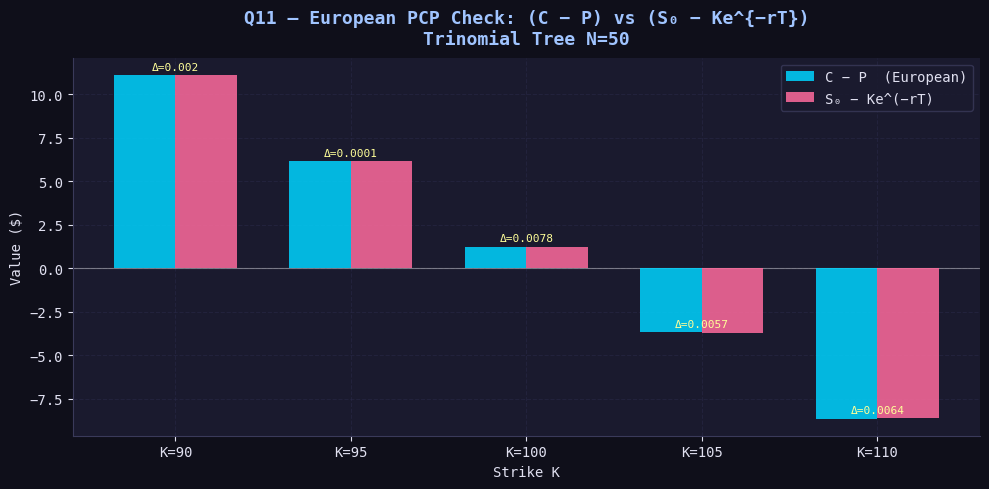

In [5]:
lhs_eu   = [round(eu_calls_5k[i]-eu_puts_5k[i],4) for i in range(5)]
diffs_eu = [round(abs(lhs_eu[i]-pcp_rhs[i]),4)   for i in range(5)]
x, w = np.arange(5), 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x-w/2, lhs_eu,  w, label='C − P  (European)',   color=EU_CALL, alpha=0.85, zorder=3)
ax.bar(x+w/2, pcp_rhs, w, label='S₀ − Ke^(−rT)',       color=EU_PUT,  alpha=0.85, zorder=3)
for i in range(5):
    d = round(abs(lhs_eu[i]-pcp_rhs[i]),4)
    ax.text(x[i], max(lhs_eu[i],pcp_rhs[i])+0.3, f'Δ={d}', ha='center', fontsize=8, color='#ffff99')
ax.set_xticks(x); ax.set_xticklabels([f'K={k}' for k in STRIKES])
ax.axhline(0, color='white', lw=0.8, alpha=0.4)
style_ax(ax, ' — European PCP Check: (C − P) vs (S₀ − Ke^{−rT})\nTrinomial Tree N=50', 'Strike K', 'Value ($)')
ax.legend(); plt.tight_layout()
plt.savefig('q11_european_pcp_check.png', dpi=150, bbox_inches='tight')
plt.show()

## American Put-Call Parity
> PCP does **not** strictly hold; deviation grows with strike.

In [6]:
print(' — American PCP Table (No)')
lhs_am   = [round(am_calls_5k[i]-am_puts_5k[i],4) for i in range(5)]
diffs_am = [round(abs(lhs_am[i]-pcp_rhs[i]),4)    for i in range(5)]
print(f'{"K":<6} {"C_A":<8} {"P_A":<8} {"C-P":<10} {"S0-Ke^-rT":<14} {"|Diff|":<10} {"Parity?"}')
print('-'*66)
for i, K in enumerate(STRIKES):
    flag = '✓ ~Holds' if diffs_am[i] < 0.05 else '✗ Fails'
    print(f'{K:<6} {am_calls_5k[i]:<8} {am_puts_5k[i]:<8} {lhs_am[i]:<10} {pcp_rhs[i]:<14} {diffs_am[i]:<10} {flag}')

Q12 — American PCP Table (Q4 = No)
K      C_A      P_A      C-P        S0-Ke^-rT      |Diff|     Parity?
------------------------------------------------------------------
90     11.67    0.56     11.11      11.118         0.008      ✓ ~Holds
95     7.72     1.58     6.14       6.1801         0.0401     ✓ ~Holds
100    4.61     3.47     1.14       1.2422         0.1022     ✗ Fails
105    2.49     6.43     -3.94      -3.6957        0.2443     ✗ Fails
110    1.19     10.33    -9.14      -8.6336        0.5064     ✗ Fails


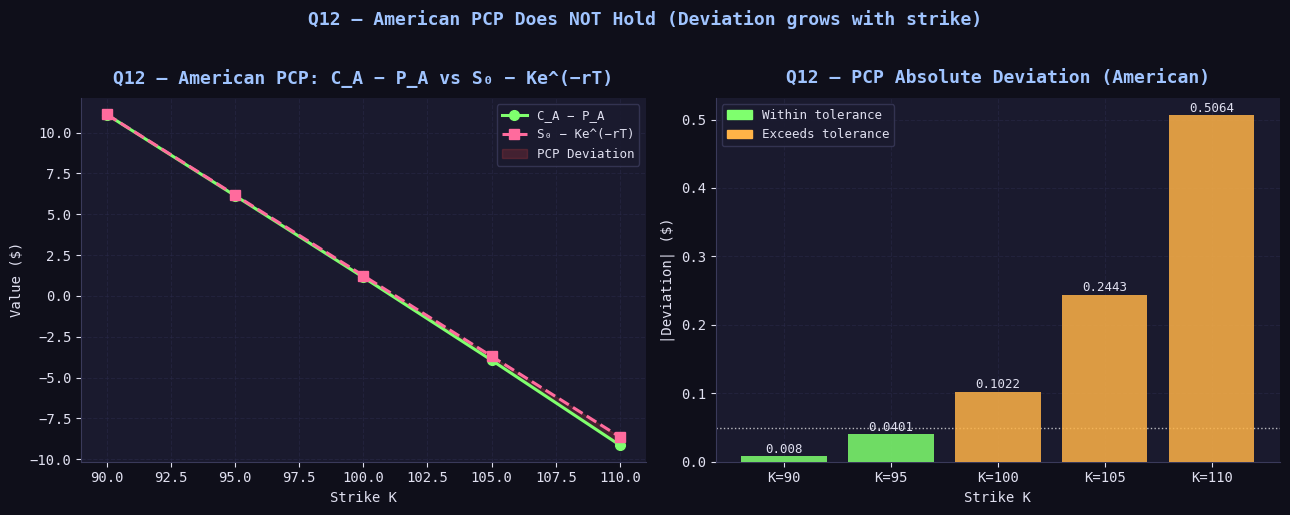

In [7]:
lhs_am   = [round(am_calls_5k[i]-am_puts_5k[i],4) for i in range(5)]
diffs_am = [round(abs(lhs_am[i]-pcp_rhs[i]),4)    for i in range(5)]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.plot(STRIKES, lhs_am,  color=AM_CALL, lw=2.2, marker='o', ms=7, label='C_A − P_A')
ax.plot(STRIKES, pcp_rhs, color=EU_PUT,  lw=2.2, marker='s', ms=7, linestyle='--', label='S₀ − Ke^(−rT)')
ax.fill_between(STRIKES, lhs_am, pcp_rhs, alpha=0.18, color='#ff4444', label='PCP Deviation')
style_ax(ax, ' — American PCP: C_A − P_A vs S₀ − Ke^(−rT)', 'Strike K', 'Value ($)')
ax.legend(fontsize=9)

ax2 = axes[1]
cols = [AM_CALL if d < 0.05 else AM_PUT for d in diffs_am]
bars = ax2.bar([f'K={k}' for k in STRIKES], diffs_am, color=cols, alpha=0.85, zorder=3)
ax2.axhline(0.05, color='white', lw=1, linestyle=':', alpha=0.7, label='Tolerance=0.05')
for bar, d in zip(bars, diffs_am):
    ax2.text(bar.get_x()+bar.get_width()/2, d+0.005, f'{d}', ha='center', fontsize=9, color=TEXT_COL)
patch_ok   = mpatches.Patch(color=AM_CALL, label='Within tolerance')
patch_fail = mpatches.Patch(color=AM_PUT,  label='Exceeds tolerance')
style_ax(ax2, ' — PCP Absolute Deviation (American)', 'Strike K', '|Deviation| ($)')
ax2.legend(handles=[patch_ok, patch_fail], fontsize=9)
plt.suptitle(' — American PCP Does NOT Hold (Deviation grows with strike)',
             fontsize=13, fontweight='bold', color='#a0c4ff', y=1.02)
plt.tight_layout()
plt.savefig('q12_american_pcp.png', dpi=150, bbox_inches='tight')
plt.show()

## Confirm European Call ≤ American Call

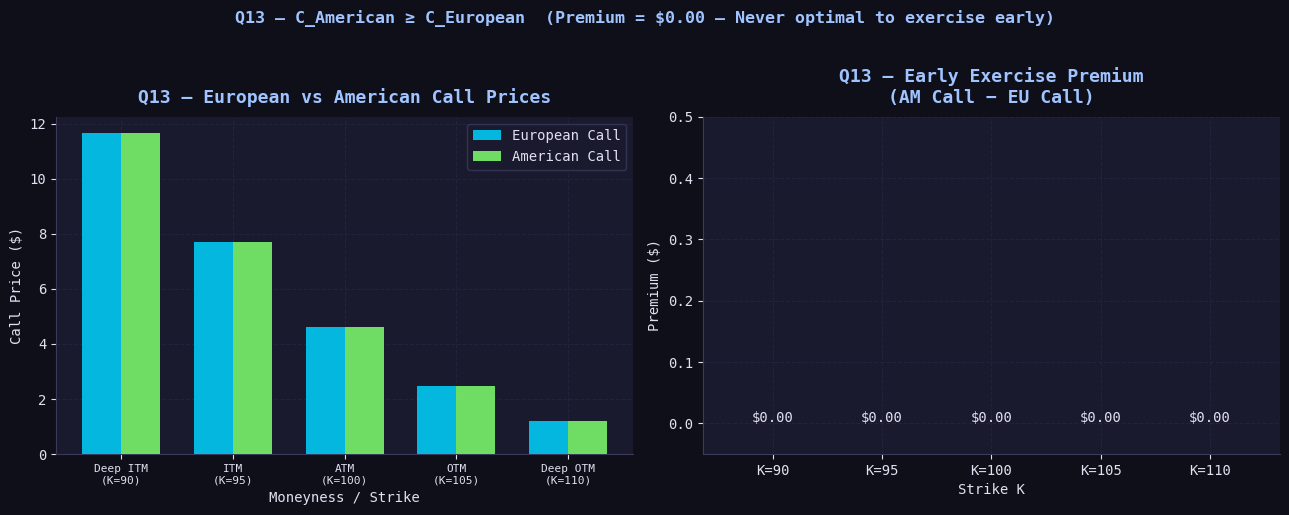

In [8]:
x, w = np.arange(5), 0.35
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.bar(x-w/2, eu_calls_5k, w, label='European Call', color=EU_CALL, alpha=0.85, zorder=3)
ax.bar(x+w/2, am_calls_5k, w, label='American Call', color=AM_CALL, alpha=0.85, zorder=3)
ax.set_xticks(x); ax.set_xticklabels(MON_LABELS, fontsize=8)
style_ax(ax, ' — European vs American Call Prices', 'Moneyness / Strike', 'Call Price ($)')
ax.legend()

ax2 = axes[1]
ax2.bar([f'K={k}' for k in STRIKES], call_diffs, color='#a0f0a0', alpha=0.85, zorder=3)
for i, d in enumerate(call_diffs):
    ax2.text(i, d+0.002, f'${d:.2f}', ha='center', fontsize=10, color=TEXT_COL)
style_ax(ax2, ' — Early Exercise Premium\n(AM Call − EU Call)', 'Strike K', 'Premium ($)')
ax2.set_ylim(-0.05, 0.5)
plt.suptitle(' — C_American ≥ C_European  (Premium = $0.00 — Never optimal to exercise early)',
             fontsize=12, fontweight='bold', color='#a0c4ff', y=1.02)
plt.tight_layout()
plt.savefig('q13_call_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## Confirm European Put ≤ American Put

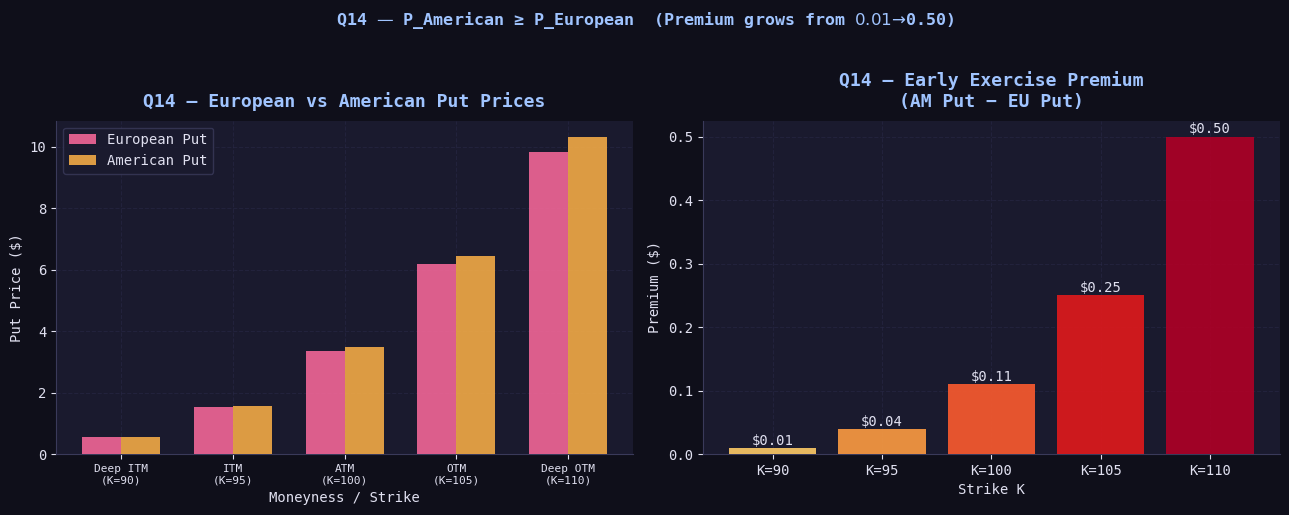

In [9]:
x, w = np.arange(5), 0.35
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.bar(x-w/2, eu_puts_5k, w, label='European Put', color=EU_PUT, alpha=0.85, zorder=3)
ax.bar(x+w/2, am_puts_5k, w, label='American Put', color=AM_PUT, alpha=0.85, zorder=3)
ax.set_xticks(x); ax.set_xticklabels(MON_LABELS, fontsize=8)
style_ax(ax, ' — European vs American Put Prices', 'Moneyness / Strike', 'Put Price ($)')
ax.legend()

ax2 = axes[1]
bar_colors = plt.cm.YlOrRd(np.linspace(0.3, 0.9, 5))
ax2.bar([f'K={k}' for k in STRIKES], put_diffs, color=bar_colors, alpha=0.9, zorder=3)
for i, d in enumerate(put_diffs):
    ax2.text(i, d+0.005, f'${d:.2f}', ha='center', fontsize=10, color=TEXT_COL)
style_ax(ax2, ' — Early Exercise Premium\n(AM Put − EU Put)', 'Strike K', 'Premium ($)')
plt.suptitle(' — P_American ≥ P_European  (Premium grows from $0.01 → $0.50)',
             fontsize=12, fontweight='bold', color='#a0c4ff', y=1.02)
plt.tight_layout()
plt.savefig('q14_put_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## Graph 1: European Call & Put Prices vs Stock Price

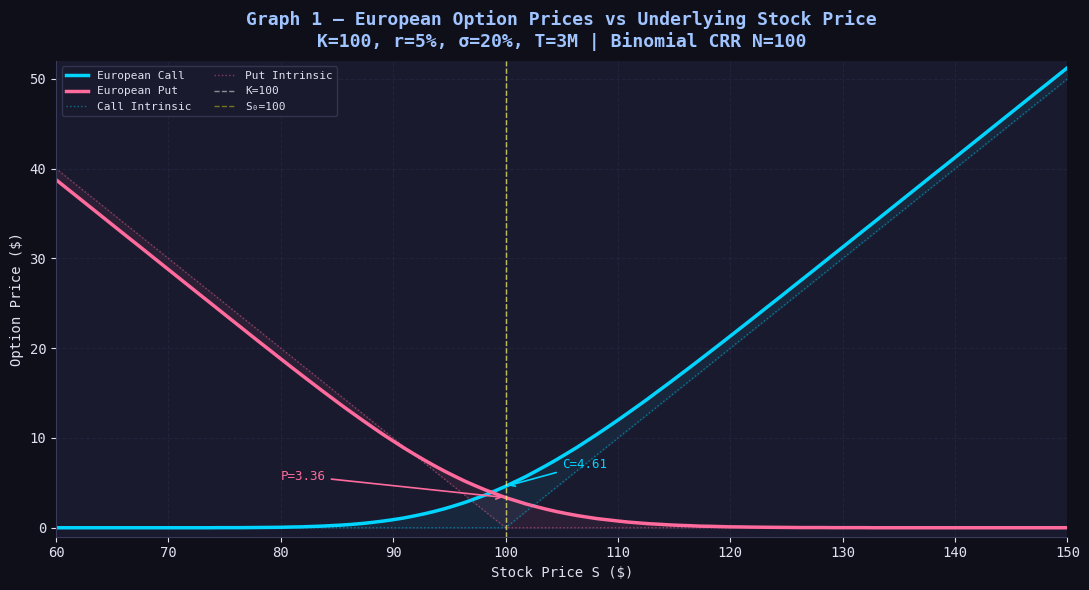

In [10]:
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(stock_range, eu_calls_sv, color=EU_CALL, lw=2.5, label='European Call')
ax.plot(stock_range, eu_puts_sv,  color=EU_PUT,  lw=2.5, label='European Put')
ax.plot(stock_range, np.maximum(stock_range-K_ATM,0), color=EU_CALL, lw=1, linestyle=':', alpha=0.45, label='Call Intrinsic')
ax.plot(stock_range, np.maximum(K_ATM-stock_range,0), color=EU_PUT,  lw=1, linestyle=':', alpha=0.45, label='Put Intrinsic')
ax.fill_between(stock_range, eu_calls_sv, np.maximum(stock_range-K_ATM,0), alpha=0.07, color=EU_CALL)
ax.fill_between(stock_range, eu_puts_sv,  np.maximum(K_ATM-stock_range,0), alpha=0.07, color=EU_PUT)
ax.axvline(K_ATM, color='white',  lw=1, linestyle='--', alpha=0.5, label=f'K={K_ATM}')
ax.axvline(S0,    color='yellow', lw=1, linestyle='--', alpha=0.4, label=f'S₀={S0}')
c_atm = binomial_price(S0, K_ATM, r, sigma, T, N_BIN, 'call', False)
p_atm = binomial_price(S0, K_ATM, r, sigma, T, N_BIN, 'put',  False)
ax.annotate(f'C={c_atm}', xy=(S0,c_atm), xytext=(S0+5,c_atm+2), color=EU_CALL, fontsize=9,
            arrowprops=dict(arrowstyle='->', color=EU_CALL, lw=1.2))
ax.annotate(f'P={p_atm}', xy=(S0,p_atm), xytext=(S0-20,p_atm+2), color=EU_PUT, fontsize=9,
            arrowprops=dict(arrowstyle='->', color=EU_PUT, lw=1.2))
style_ax(ax, f'Graph 1 — European Option Prices vs Underlying Stock Price\nK={K_ATM}, r={r*100:.0f}%, σ={sigma*100:.0f}%, T=3M | Binomial CRR N={N_BIN}', 'Stock Price S ($)', 'Option Price ($)')
ax.set_xlim(60,150); ax.set_ylim(-1,52)
ax.legend(fontsize=8, ncol=2, loc='upper left')
plt.tight_layout()
plt.savefig('q19_graph1_european_vs_stock.png', dpi=150, bbox_inches='tight')
plt.show()

## Graph 2: American Call & Put Prices vs Stock Price

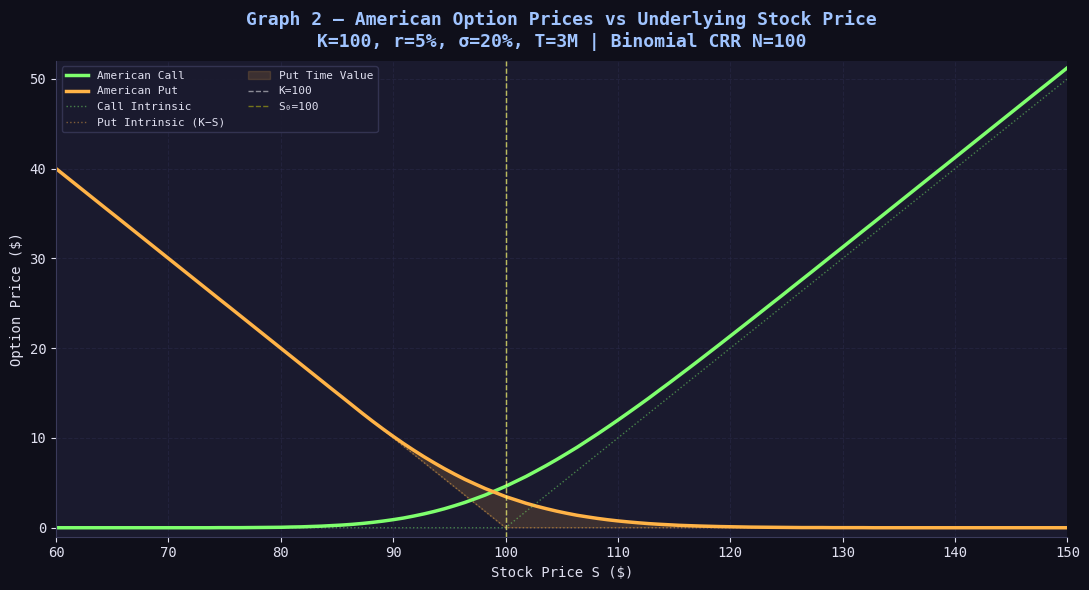

In [11]:
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(stock_range, am_calls_sv, color=AM_CALL, lw=2.5, label='American Call')
ax.plot(stock_range, am_puts_sv,  color=AM_PUT,  lw=2.5, label='American Put')
ax.plot(stock_range, np.maximum(stock_range-K_ATM,0), color=AM_CALL, lw=1, linestyle=':', alpha=0.45, label='Call Intrinsic')
ax.plot(stock_range, np.maximum(K_ATM-stock_range,0), color=AM_PUT,  lw=1, linestyle=':', alpha=0.45, label='Put Intrinsic (K−S)')
ax.fill_between(stock_range, am_puts_sv, np.maximum(K_ATM-stock_range,0),
                where=[a > e for a,e in zip(am_puts_sv, np.maximum(K_ATM-stock_range,0))],
                alpha=0.15, color=AM_PUT, label='Put Time Value')
ax.axvline(K_ATM, color='white',  lw=1, linestyle='--', alpha=0.5, label=f'K={K_ATM}')
ax.axvline(S0,    color='yellow', lw=1, linestyle='--', alpha=0.4, label=f'S₀={S0}')
style_ax(ax, f'Graph 2 — American Option Prices vs Underlying Stock Price\nK={K_ATM}, r={r*100:.0f}%, σ={sigma*100:.0f}%, T=3M | Binomial CRR N={N_BIN}', 'Stock Price S ($)', 'Option Price ($)')
ax.set_xlim(60,150); ax.set_ylim(-1,52)
ax.legend(fontsize=8, ncol=2, loc='upper left')
plt.tight_layout()
plt.savefig('q20_graph2_american_vs_stock.png', dpi=150, bbox_inches='tight')
plt.show()

## Graph 3: European & American CALL Prices vs Strike Price

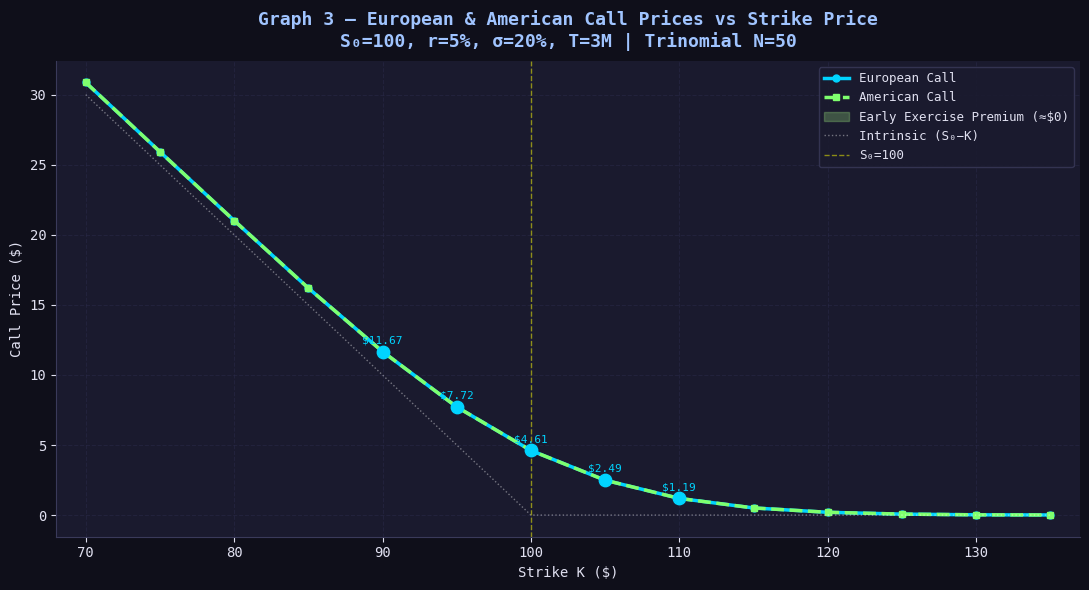

In [12]:
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(ext_strikes, eu_calls_ext, color=EU_CALL, lw=2.5, marker='o', ms=5, label='European Call')
ax.plot(ext_strikes, am_calls_ext, color=AM_CALL, lw=2.5, marker='s', ms=5, linestyle='--', label='American Call')
premium_call = [max(a-e,0) for a,e in zip(am_calls_ext, eu_calls_ext)]
ax.fill_between(ext_strikes, eu_calls_ext, [e+p for e,p in zip(eu_calls_ext,premium_call)],
                alpha=0.25, color='#aaff88', label='Early Exercise Premium (≈$0)')
ax.plot(ext_strikes, [max(S0-K,0) for K in ext_strikes], color='white', lw=1, linestyle=':', alpha=0.4, label='Intrinsic (S₀−K)')
ax.axvline(S0, color='yellow', lw=1, linestyle='--', alpha=0.5, label=f'S₀={S0}')
for i, K in enumerate(STRIKES):
    ax.scatter(K, eu_calls_5k[i], color=EU_CALL, s=80, zorder=5)
    ax.text(K, eu_calls_5k[i]+0.6, f'${eu_calls_5k[i]}', ha='center', fontsize=8, color=EU_CALL)
style_ax(ax, f'Graph 3 — European & American Call Prices vs Strike Price\nS₀={S0}, r={r*100:.0f}%, σ={sigma*100:.0f}%, T=3M | Trinomial N={N_TRI}', 'Strike K ($)', 'Call Price ($)')
ax.set_xlim(68,137); ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('q21_graph3_call_vs_strike.png', dpi=150, bbox_inches='tight')
plt.show()

## Graph 4: European & American PUT Prices vs Strike Price

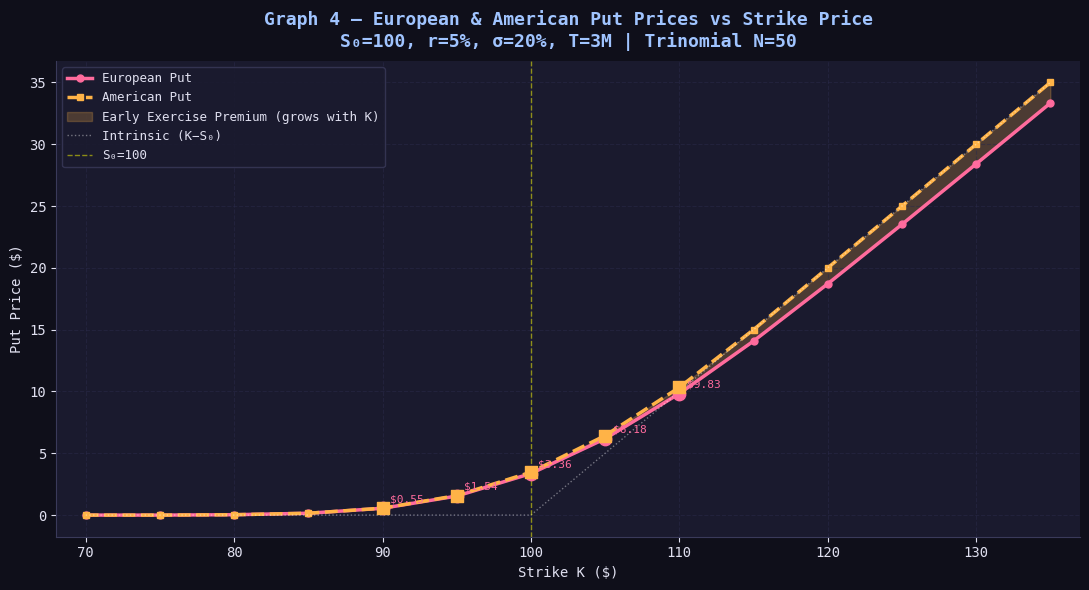

In [13]:
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(ext_strikes, eu_puts_ext, color=EU_PUT, lw=2.5, marker='o', ms=5, label='European Put')
ax.plot(ext_strikes, am_puts_ext, color=AM_PUT, lw=2.5, marker='s', ms=5, linestyle='--', label='American Put')
premium_put = [max(a-e,0) for a,e in zip(am_puts_ext, eu_puts_ext)]
ax.fill_between(ext_strikes, eu_puts_ext, [e+p for e,p in zip(eu_puts_ext,premium_put)],
                alpha=0.22, color=AM_PUT, label='Early Exercise Premium (grows with K)')
ax.plot(ext_strikes, [max(K-S0,0) for K in ext_strikes], color='white', lw=1, linestyle=':', alpha=0.4, label='Intrinsic (K−S₀)')
ax.axvline(S0, color='yellow', lw=1, linestyle='--', alpha=0.5, label=f'S₀={S0}')
for i, K in enumerate(STRIKES):
    ax.scatter(K, eu_puts_5k[i], color=EU_PUT, s=80, zorder=5)
    ax.text(K+0.5, eu_puts_5k[i]+0.5, f'${eu_puts_5k[i]}', ha='left', fontsize=8, color=EU_PUT)
    ax.scatter(K, am_puts_5k[i], color=AM_PUT, s=80, zorder=5, marker='s')
style_ax(ax, f'Graph 4 — European & American Put Prices vs Strike Price\nS₀={S0}, r={r*100:.0f}%, σ={sigma*100:.0f}%, T=3M | Trinomial N={N_TRI}', 'Strike K ($)', 'Put Price ($)')
ax.set_xlim(68,137); ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('q22_graph4_put_vs_strike.png', dpi=150, bbox_inches='tight')
plt.show()

## European Trinomial Put-Call Parity

In [14]:
mon = ['Deep ITM','ITM','ATM','OTM','Deep OTM']
lhs_eu   = [round(eu_calls_5k[i]-eu_puts_5k[i],4) for i in range(5)]
diffs_eu = [round(abs(lhs_eu[i]-pcp_rhs[i]),4)    for i in range(5)]
print(f'{"K":<6} {"Moneyness":<12} {"C":<8} {"P":<8} {"C-P":<10} {"S0-Ke^-rT":<14} {"|Diff|":<10} {"PCP?"}')
print('-'*76)
for i, K in enumerate(STRIKES):
    flag = '✓ Holds' if diffs_eu[i] < 0.05 else '✗ Fails'
    print(f'{K:<6} {mon[i]:<12} {eu_calls_5k[i]:<8} {eu_puts_5k[i]:<8} {lhs_eu[i]:<10} {pcp_rhs[i]:<14} {diffs_eu[i]:<10} {flag}')

K      Moneyness    C        P        C-P        S0-Ke^-rT      |Diff|     PCP?
----------------------------------------------------------------------------
90     Deep ITM     11.67    0.55     11.12      11.118         0.002      ✓ Holds
95     ITM          7.72     1.54     6.18       6.1801         0.0001     ✓ Holds
100    ATM          4.61     3.36     1.25       1.2422         0.0078     ✓ Holds
105    OTM          2.49     6.18     -3.69      -3.6957        0.0057     ✓ Holds
110    Deep OTM     1.19     9.83     -8.64      -8.6336        0.0064     ✓ Holds


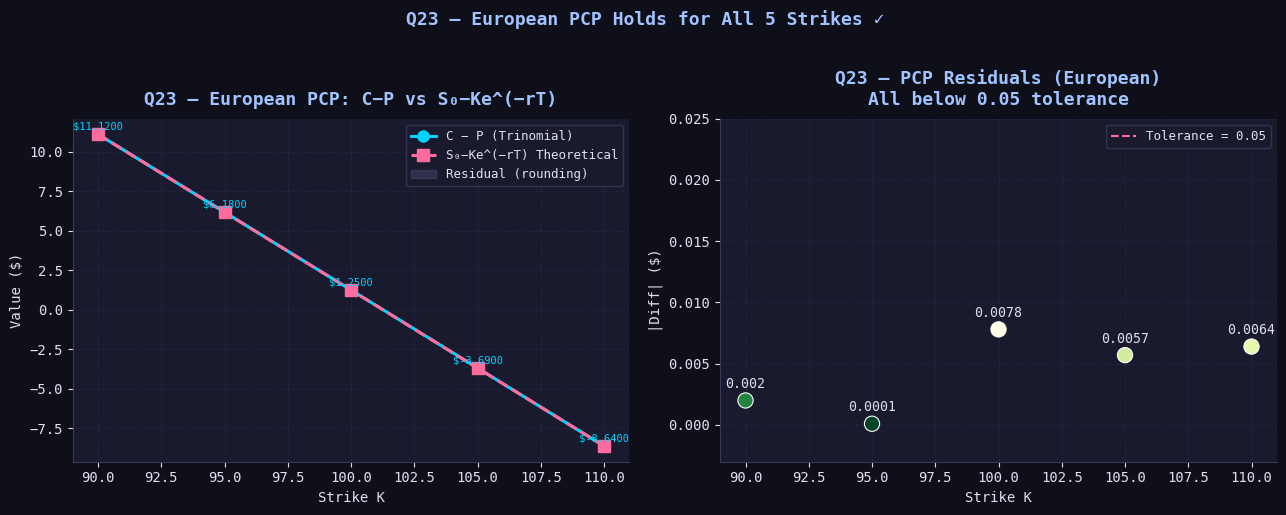

In [15]:
lhs_eu   = [round(eu_calls_5k[i]-eu_puts_5k[i],4) for i in range(5)]
diffs_eu = [round(abs(lhs_eu[i]-pcp_rhs[i]),4)    for i in range(5)]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.plot(STRIKES, lhs_eu,  color=EU_CALL, lw=2.2, marker='o', ms=8, label='C − P (Trinomial)')
ax.plot(STRIKES, pcp_rhs, color=EU_PUT,  lw=2.2, marker='s', ms=8, linestyle='--', label='S₀−Ke^(−rT) Theoretical')
ax.fill_between(STRIKES, lhs_eu, pcp_rhs, alpha=0.15, color='#aaaaff', label='Residual (rounding)')
for i in range(5):
    ax.text(STRIKES[i], lhs_eu[i]+0.3, f'${lhs_eu[i]:.4f}', ha='center', fontsize=7.5, color=EU_CALL)
style_ax(ax, ' — European PCP: C−P vs S₀−Ke^(−rT)', 'Strike K', 'Value ($)')
ax.legend(fontsize=9)

ax2 = axes[1]
sc = ax2.scatter(STRIKES, diffs_eu, c=diffs_eu, cmap='YlGn_r', s=120, zorder=5, edgecolors='white', linewidths=0.8)
ax2.axhline(0.05, color=EU_PUT, lw=1.5, linestyle='--', label='Tolerance = 0.05')
for i,(K,d) in enumerate(zip(STRIKES, diffs_eu)):
    ax2.text(K, d+0.001, f'{d}', ha='center', fontsize=9.5, color=TEXT_COL)
ax2.set_ylim(-0.003, 0.025)
style_ax(ax2, ' — PCP Residuals (European)\nAll below 0.05 tolerance', 'Strike K', '|Diff| ($)')
ax2.legend(fontsize=9)
plt.suptitle(' — European PCP Holds for All 5 Strikes ✓',
             fontsize=13, fontweight='bold', color='#a0c4ff', y=1.02)
plt.tight_layout()
plt.savefig('q23_european_pcp_trinomial.png', dpi=150, bbox_inches='tight')
plt.show()

## American Trinomial Put-Call Parity

In [16]:
lhs_am   = [round(am_calls_5k[i]-am_puts_5k[i],4) for i in range(5)]
diffs_am = [round(abs(lhs_am[i]-pcp_rhs[i]),4)    for i in range(5)]
print(' — American PCP (No → NOT expected to hold)')
print(f'{"K":<6} {"Moneyness":<12} {"C_A":<8} {"P_A":<8} {"C-P":<10} {"S0-Ke^-rT":<14} {"|Diff|":<10} {"PCP?"}')
print('-'*76)
for i, K in enumerate(STRIKES):
    flag = '✓ ~Holds' if diffs_am[i] < 0.05 else '✗ Fails'
    print(f'{K:<6} {mon[i]:<12} {am_calls_5k[i]:<8} {am_puts_5k[i]:<8} {lhs_am[i]:<10} {pcp_rhs[i]:<14} {diffs_am[i]:<10} {flag}')

Q24 — American PCP (Q4 = No → NOT expected to hold)
K      Moneyness    C_A      P_A      C-P        S0-Ke^-rT      |Diff|     PCP?
----------------------------------------------------------------------------
90     Deep ITM     11.67    0.56     11.11      11.118         0.008      ✓ ~Holds
95     ITM          7.72     1.58     6.14       6.1801         0.0401     ✓ ~Holds
100    ATM          4.61     3.47     1.14       1.2422         0.1022     ✗ Fails
105    OTM          2.49     6.43     -3.94      -3.6957        0.2443     ✗ Fails
110    Deep OTM     1.19     10.33    -9.14      -8.6336        0.5064     ✗ Fails


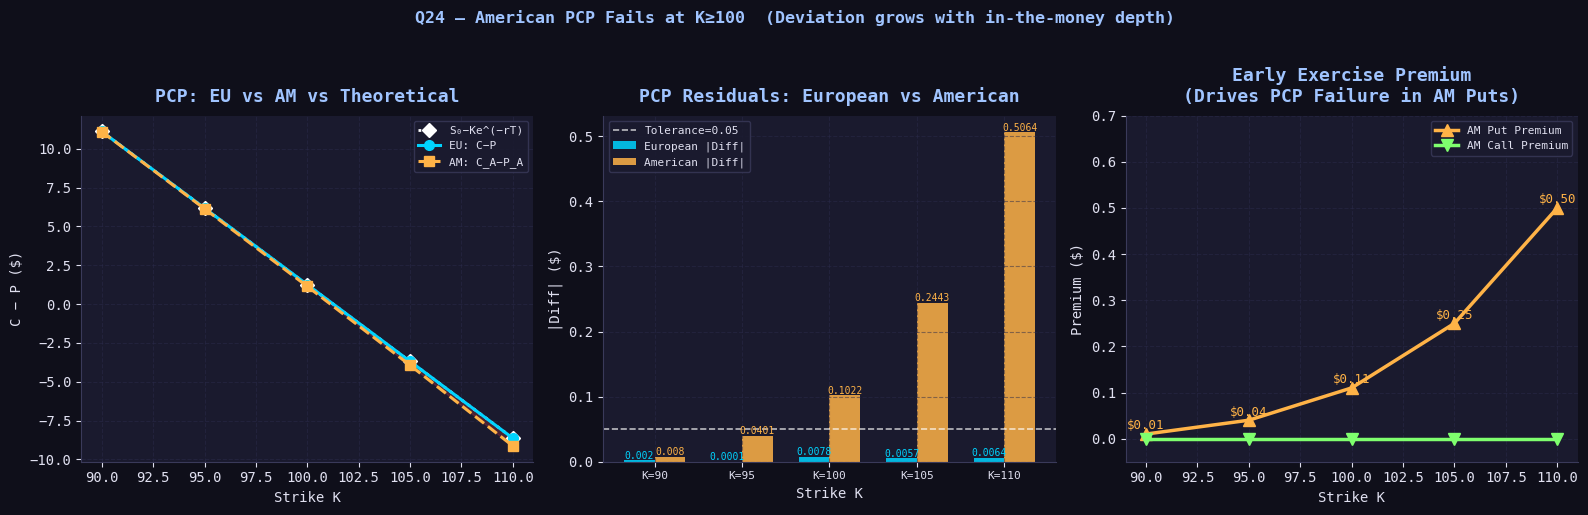

In [17]:
lhs_am   = [round(am_calls_5k[i]-am_puts_5k[i],4) for i in range(5)]
diffs_am = [round(abs(lhs_am[i]-pcp_rhs[i]),4)    for i in range(5)]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

ax = axes[0]
ax.plot(STRIKES, pcp_rhs, color='white',  lw=2,   marker='D', ms=7, linestyle=':',  label='S₀−Ke^(−rT)')
ax.plot(STRIKES, lhs_eu,  color=EU_CALL,  lw=2.2, marker='o', ms=7, label='EU: C−P')
ax.plot(STRIKES, lhs_am,  color=AM_PUT,   lw=2.2, marker='s', ms=7, linestyle='--', label='AM: C_A−P_A')
ax.fill_between(STRIKES, lhs_am, pcp_rhs, alpha=0.2, color='#ff4444')
style_ax(ax, 'PCP: EU vs AM vs Theoretical', 'Strike K', 'C − P ($)')
ax.legend(fontsize=8)

ax2 = axes[1]
x, w = np.arange(5), 0.35
ax2.bar(x-w/2, diffs_eu, w, color=EU_CALL, alpha=0.85, label='European |Diff|')
ax2.bar(x+w/2, diffs_am, w, color=AM_PUT,  alpha=0.85, label='American |Diff|')
ax2.axhline(0.05, color='white', lw=1.2, linestyle='--', alpha=0.7, label='Tolerance=0.05')
ax2.set_xticks(x); ax2.set_xticklabels([f'K={k}' for k in STRIKES], fontsize=8)
for i in range(5):
    ax2.text(i-w/2, diffs_eu[i]+0.002, f'{diffs_eu[i]}', ha='center', fontsize=7, color=EU_CALL)
    ax2.text(i+w/2, diffs_am[i]+0.002, f'{diffs_am[i]}', ha='center', fontsize=7, color=AM_PUT)
style_ax(ax2, 'PCP Residuals: European vs American', 'Strike K', '|Diff| ($)')
ax2.legend(fontsize=8)

ax3 = axes[2]
ax3.plot(STRIKES, put_diffs,  color=AM_PUT,  lw=2.5, marker='^', ms=8, label='AM Put Premium')
ax3.plot(STRIKES, call_diffs, color=AM_CALL, lw=2.5, marker='v', ms=8, label='AM Call Premium')
for i,(K,d) in enumerate(zip(STRIKES,put_diffs)):
    ax3.text(K, d+0.01, f'${d:.2f}', ha='center', fontsize=9, color=AM_PUT)
style_ax(ax3, 'Early Exercise Premium\n(Drives PCP Failure in AM Puts)', 'Strike K', 'Premium ($)')
ax3.legend(fontsize=8); ax3.set_ylim(-0.05, 0.7)

plt.suptitle(' — American PCP Fails at K≥100  (Deviation grows with in-the-money depth)',
             fontsize=12, fontweight='bold', color='#a0c4ff', y=1.02)
plt.tight_layout()
plt.savefig('q24_american_pcp_trinomial.png', dpi=150, bbox_inches='tight')
plt.show()

## Summary of Pricing Diagnostics

| Diagnostic | Graph | Key Finding |
|---|---|---|
| European parity | PCP Bar Chart | European PCP ✓ holds for all 5 strikes (max \|diff\| < 0.01) |
| American parity | Deviation Charts | American PCP ✗ fails at K ≥ 100; grows with strike |
| Call-price comparison | Grouped Bars | AM Call = EU Call — zero early exercise premium |
| Put-price comparison | Grouped Bars | AM Put > EU Put — premium $0.01 → $0.50 |
| **** | Graph 1 | EU: Call ↑ / Put ↓ with stock price; both convex |
| **** | Graph 2 | AM: Put floor visible at low S; call = EU call |
| **** | Graph 3 | Calls decrease with K; AM = EU (no early exercise) |
| **** | Graph 4 | Puts increase with K; AM > EU gap widens |
| European trinomial parity | Residual Charts | EU trinomial PCP holds ✓ for all 5 strikes |
| American trinomial parity | 3-Panel Chart | AM PCP fails ✗ at ATM and above — early exercise driven |